# Integridad de summaries: metadatos laterales sin alterar el wire

## Pregunta, utilidad y continuidad del programa

El laboratorio desarrolla Welford desplazado, escalado, autoescala y fusión Chan; el 2-nov se añadió un payload numérico `MOMENTS_V1` que consume C++20. Ese contrato transporta suficientes estadísticas pero omite historial de diagnósticos. Si el consumidor reinicia un contador a cero, ¿cómo distinguir el cero medido de desconocido sin modificar las siete columnas numéricas? El valor práctico es revisar una exportación sin atribuir propiedades que no están en los datos.

## Fórmula, unidades y alcance

Para valores `x` con unidad U, el normalizador usa `y=x/2^e`; `a` y `b` están en unidades de `y`, y `Q=Σ(y−(a+b))²`. La varianza calculada sigue siendo `s_d²=2^(2e) Q/(n−d)`, `d∈{0,1}`, `n>d`; su unidad es U². El sobre no cambia `n,e,a,b,Q` ni el estimador. No hay nueva derivación estadística.

H1 fijada antes del experimento: 12/12 payloads y categorías diagnósticas round-trip exactos. H2: una mutación de payload o metadata sin recalcular digest falla. El benchmark compara envelope estructurado contra un JSON sidecar plano con **la misma información y ambos hashes**; no se predice superioridad temporal.

In [1]:
import json
from pathlib import Path
from IPython.display import display, Image
from src.audit_envelope import create_envelope, dumps_envelope, loads_envelope
from src.transport import export_state
from src.dynamic import DynamicMoments

cfg = json.loads(Path('config_envelope.json').read_text())
cfg

Out[0]: 
{'question': 'Can a sidecar preserve diagnostic coverage and declared provenance for MOMENTS_V1 without changing the numeric wire contract?',
 'hypothesis': 'Across 12 deterministic synthetic states, all payload bytes and the distinctions tracked/partial/unknown round-trip exactly; any payload or metadata mutation is rejected.',
 'threshold': '12/12 exact payload round-trips; 12/12 metadata-state round-trips; 100% detection of the two tested mutation classes.',
 'baseline': 'Flat canonical JSON sidecar with the same fields and payload/record SHA-256 digests.',
 'data': 'No external dataset. Deterministic synthetic summaries created from values using seed 831103.',
 'seed': 831103,
 'scenario_count': 12,
 'repetitions': 5,
 'hardware': 'See results/envelope_summary.json and CI; benchmark only reports local runtime, without portable performance claim.',
 'runtime': 'Python 3.12; project pins in requirements.txt; C++ MOMENTS_V1 consumer unchanged.',
 'format_scope': 'Local Python

## Semántica de disponibilidad

`tracked` contiene todos los contadores enteros, y el cero significa medido. `partial` contiene un subconjunto propio de contadores; los demás permanecen `null`. `unknown` contiene sólo `null`. Esta distinción es un invariante de contrato, no inferencia estadística. `partition_id` y `source_id` son declaraciones del productor; ni hash ni etiqueta prueban disjunción o identidad.

In [2]:
state = DynamicMoments()
for x in [1., 2., 3.]: state.push(x)
wire = export_state(state)
unknown = create_envelope(wire, source_id='synthetic-fixture', partition_id='chunk-A', diagnostic_state='unknown')
tracked_zero = create_envelope(wire, source_id='synthetic-fixture', partition_id='chunk-A', diagnostic_state='tracked', diagnostic_counts={'rounded_to_zero':0,'normalization_failures':0,'rebase_events':0})
assert loads_envelope(dumps_envelope(unknown))['diagnostics']['counts']['rounded_to_zero'] is None
assert loads_envelope(dumps_envelope(tracked_zero))['diagnostics']['counts']['rounded_to_zero'] == 0
print('Wire original:', wire)
print('Unknown:', unknown['diagnostics'])
print('Tracked zero:', tracked_zero['diagnostics'])

Wire original: MOMENTS_V1 0 0 0x0.0p+0 0x0.0p+0 0x0.0p+0 0
Unknown: {'state': 'unknown', 'counts': {'rounded_to_zero': None, 'normalization_failures': None, 'rebase_events': None}}
Tracked zero: {'state': 'tracked', 'counts': {'rounded_to_zero': 0, 'normalization_failures': 0, 'rebase_events': 0}}


## Hashes y propiedades que no se conservan

`h_p=SHA256(ASCII(payload))`; `h_e=SHA256(JSONlocal(document sin h_e))`. El módulo ordena claves JSON y compacta separadores bajo Python. RFC 8785 especifica JCS para canonicalización interoperable; este prototipo no la implementa. Los hashes detectan cambios accidentales según bytes codificados, no autentican: un editor puede recalcularlos. No se afirma firma, seguridad frente a adversario con escritura, ni identidad de fuente.

In [3]:
tampered = dict(unknown)
tampered['provenance'] = dict(unknown['provenance'])
tampered['provenance']['partition_id'] = 'changed'
try:
    from src.audit_envelope import verify_envelope
    verify_envelope(tampered)
except ValueError as exc:
    print('Metadata mutada rechazada:', exc)
else:
    raise AssertionError('Metadata mutation passed')
summary = json.loads(Path('results/envelope_summary.json').read_text())
assert summary['all_payload_roundtrips_exact'] and summary['all_metadata_states_preserved']
summary

Metadata mutada rechazada: envelope digest mismatch
Out[0]: 
{'seed': 831103,
 'scenarios': 12,
 'repetitions_per_method': 5,
 'records': 120,
 'all_payload_roundtrips_exact': True,
 'all_metadata_states_preserved': True,
 'methods': {'envelope': {'median_utf8_bytes': 490.0,
   'median_roundtrip_ns': 43601.0,
   'p95_roundtrip_ns': 166682},
  'sidecar': {'median_utf8_bytes': 460.0,
   'median_roundtrip_ns': 15639.0,
   'p95_roundtrip_ns': 23656}},
 'interpretation': 'synthetic local serialization benchmark; no throughput superiority claim',
 'baseline_semantics': 'flat JSON sidecar with same fields, SHA-256 payload digest, and SHA-256 record digest'}


## Comparación, ablaciones y resultados

Ambos métodos guardan los mismos campos; el sidecar plano es un baseline competitivo, no un strawman. Se reportan tamaño UTF-8 y tiempos locales, que pueden favorecer cualquiera. Ablación V1 solo no conserva status; quitar el digest del envelope no detecta metadata alterada; reemplazar `null` por cero destruye distinción. Los casos son sintéticos y no demuestran que una implementación de ingestión real reporte correctamente sus contadores.

{
  "seed": 831103,
  "scenarios": 12,
  "repetitions_per_method": 5,
  "records": 120,
  "all_payload_roundtrips_exact": true,
  "all_metadata_states_preserved": true,
  "methods": {
    "envelope": {
      "median_utf8_bytes": 490.0,
      "median_roundtrip_ns": 43601.0,
      "p95_roundtrip_ns": 166682
    },
    "sidecar": {
      "median_utf8_bytes": 460.0,
      "median_roundtrip_ns": 15639.0,
      "p95_roundtrip_ns": 23656
    }
  },
  "interpretation": "synthetic local serialization benchmark; no throughput superiority claim",
  "baseline_semantics": "flat JSON sidecar with same fields, SHA-256 payload digest, and SHA-256 record digest"
}


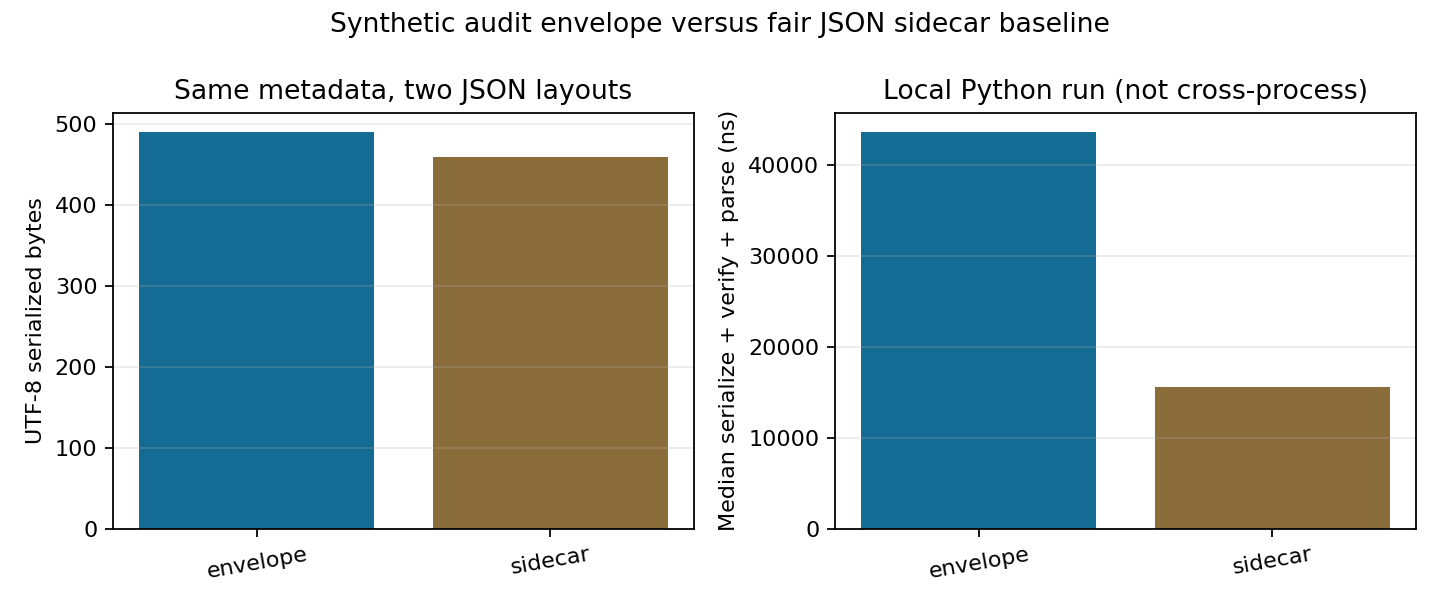

In [4]:
print(json.dumps(summary, indent=2))
display(Image(filename='results/envelope_audit.png'))

## Fallos, conclusión y siguiente experimento

Sin JCS, el JSON no tiene contrato byte-a-byte entre lenguajes; sin firma no hay autenticidad; etiquetas no demuestran particiones disjuntas; los diagnósticos no se miden ni se recolectan aquí. El resultado positivo se limita a la distinción de disponibilidad en el productor Python y detección de cambios bajo el digest local. Conclusión: H1/H2 tienen pruebas locales; la utilidad depende de una futura instrumentación. El siguiente gate es un consumidor externo JCS sólo si aparece una necesidad real de interoperar, o preservar `unknown` ante un productor que omite historial. Fuentes verificadas y sus diferencias: `prior_art_envelope.md` y `referencias.bib`.